# Population gradients of the log loss at designed parameter configurations (run 60 architecture)

No training here. The notebook builds parameter configurations of the run 60 architecture (62-60 ReLU net on the depth-5 COB-ODT, no
biases, direct readout) and computes the population gradient of the logistic loss at each of them (full-batch over 400k points), to read
what gradient descent would do first from such a point. Two configurations for now:

1. **Ideal first layer, random second layer.** W1 = the 62 one-sided features +-u_j with norms base x 2^(-level); W2 Gaussian; W_out
   alternating +-1. The design of W2 in runs 37-62 made the *probes* align to the ODT normals; the question here is the converse: given the
   ideal features, does the gradient on W2 build the designed second layer (vetoes on the wrong side of a node, readout-aligned leaf
   weights)?
2. **Run 60's W2 and W_out, first layer collapsed onto v.** Every first-layer row is alpha v with v = u_15 + ... + u_30 and alpha chosen to
   minimise the training log loss; the 32 cue rows get a small extra component epsilon x pole x u_m. How does the gradient on the probes
   look then: does each probe get pushed toward its designed node, and how does that push compare with the pull toward the leaves?

Conventions: a "push" is minus the gradient (the direction of a descent step) projected on a unit vector; `side_j(m)` is the side of
node j on which leaf m lies; a unit's *cue reading* of leaf m is `c_u(m) = sum over the two cue rows of m of W2[u, row] x pole x ||row||`;
its *side-contrast* on an internal node j is `C_u(j) = sum over leaves m under j of side_j(m) c_u(m)`, and its *half-reading* on the
side `pole` of j is `S_u(j, pole) = sum over leaves m under j with side_j(m) = pole of c_u(m)` (so `C = S(+) - S(-)`).


In [1]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, pickle, torch
%load_ext autoreload
%autoreload 2
from layer_lenses.designed_init import NODE_LEVEL, node_ancestors, HIERARCHY_TARGETS, cue_row_identity
from layer_lenses.init_sweep import SweepRunSpec, build_data, load_tree
np.set_printoptions(linewidth=200, precision=3, suppress=True); pd.set_option("display.width", 250); dev = "cuda" if torch.cuda.is_available() else "cpu"
RESULTS = Path("../results/designed_init"); RUN60 = RESULTS / "hd2_run60_sgd_lr1_1000"; tree = load_tree(RUN60 / "tree.npz"); U = tree.w_list
z60 = np.load(RUN60 / "replay/weights.npz"); meta60 = pickle.load(open(RUN60 / "replay/meta.pkl", "rb"))
W1_60, W2_60, Wo_60 = (z60[k][0].astype(np.float64) for k in ["w__hidden_layers.0.weight", "w__hidden_layers.1.weight", "w__output_layer.weight"])       # run 60's init
CUE_ROWS = list(meta60["design"]["cue_rows"]); PROBE_ROWS = list(range(30)); unode = np.array(meta60["design"]["unit_node"]); ups = np.array(meta60["design"]["unit_path_sign"])
CUE_ID = cue_row_identity(W1_60, tree, CUE_ROWS); ROW_ID = {r: (n, p) for (n, p), r in CUE_ID.items()}; ROW_ID.update({p: HIERARCHY_TARGETS[p] for p in PROBE_ROWS})     # row -> (node, pole) by design
N_POINTS = 400_000
x, y = build_data(SweepRunSpec(tree_seed=5178, data_seed=31337, init_seed=0, batch_size=1, n_train=N_POINTS), tree)
X = torch.from_numpy(x).float().to(dev); Y = torch.from_numpy(y.astype(np.float32)).to(dev); A = x @ U.T
v = U[15:31].sum(0)                                                                                          # the sum of the level-4 normals (|v| = 4)
def side_of(j, m):
    """Side (+1 / -1) of internal node j on which node m (a descendant) lies."""
    c = m
    while (c - 1) // 2 != j: c = (c - 1) // 2
    return +1 if c == 2 * j + 2 else -1
LEAVES_UNDER = {j: [m for m in range(15, 31) if j in node_ancestors(m)] for j in range(15)}

def population_gradient(W1, W2, Wo, chunk=100_000):
    """Mean logistic loss over the sample and its gradients wrt W1, W2, Wout (the population gradient, up to sampling)."""
    P = [torch.as_tensor(np.asarray(w, dtype=np.float32), device=dev).requires_grad_(True) for w in (W1, W2, Wo)]; total = 0.0
    for i in range(0, len(X), chunk):
        xb, yb = X[i:i + chunk], Y[i:i + chunk]; f = (torch.relu(torch.relu(xb @ P[0].T) @ P[1].T) @ P[2].T).squeeze(1)
        l = torch.nn.functional.softplus(-yb * f).sum() / len(X); l.backward(); total += float(l)
    return total, [p.grad.cpu().numpy().astype(np.float64) for p in P]

def cue_readings(W1, W2):
    """c[u, m]: unit u's pole-signed, norm-weighted reading of leaf m through the cue rows (by their designed identity)."""
    nrm = np.linalg.norm(W1, axis=1); c = np.zeros((W2.shape[0], 31))
    for (m, pole), r in CUE_ID.items(): c[:, m] += W2[:, r] * pole * nrm[r]
    return c
def half_readings(c):
    """S[u, j, k] for internal j and k in (0: pole +, 1: pole -): the unit's reading summed over the leaves under j on that side; contrast C = S[..., 0] - S[..., 1]."""
    S = np.zeros((c.shape[0], 15, 2))
    for j in range(15):
        for m in LEAVES_UNDER[j]: S[:, j, 0 if side_of(j, m) > 0 else 1] += c[:, m]
    return S
def ideal_first_layer(base=np.sqrt(2.0)):
    """62 rows at +-u_j in run 60's row order (probes 0-29 on their designed (node, pole), cues 30-61 on theirs), norm base x 2^(-level)."""
    W1 = np.zeros((62, 100))
    for r, (n, p) in ROW_ID.items(): W1[r] = p * U[n] * base * 2.0 ** (-NODE_LEVEL[n])
    return W1
feature_label = np.array([f"{'+' if ROW_ID[r][1] > 0 else '-'}u{ROW_ID[r][0]}" for r in range(62)]); feature_level = np.array([NODE_LEVEL[ROW_ID[r][0]] for r in range(62)])
print(f"device {dev}; {N_POINTS} points; run 60 init loaded (W2 {W2_60.shape}, |W2 row| {np.linalg.norm(W2_60, axis=1).mean():.3f}, Wout entries {np.unique(np.round(Wo_60, 3))}); feature labels by design: {feature_label[:4]} ... {feature_label[-2:]}")


device cuda; 400000 points; run 60 init loaded (W2 (60, 62), |W2 row| 1.414, Wout entries [-0.817  0.817]); feature labels by design: ['+u0' '-u0' '+u1' '-u1'] ... ['-u30' '+u30']


## 1. Ideal first layer, random W2, alternating readout: does the gradient on W2 build the designed second layer?

W1 = `ideal_first_layer()` (norm sqrt 2 x 2^(-level), so 1.41 at the root, 0.088 for the cues), W2 ~ N(0, 2/62) (He; |row| about sqrt 2, as
the design), W_out[u] = (-1)^u. Lens prediction for the descent direction on W2 at such a point (f = 0, resid = -y/2):
`-dL/dW2[u, (j, pole)] ~ Wout[u] x S_u(j, pole) x E[relu(pole a_j) on that side]` for an internal feature, and `~ Wout[u] x pole x E|a_m|`
for a leaf feature. So every unit wants leaf features with the sign of its readout (a label-aligned leaf reading), and it wants the feature of
side `pole` of node j with the sign of its own half-reading on that side times its readout: a **veto** (negative weight) on the side where the
unit's leaf reading is opposed to its readout, a positive weight on the other side. The cells test this on the measured gradient, and on its **label part**: the gradient at f -> 0 with the same gates (the residual -y sigma(-y f)
replaced by -y/2), which is what the lens formula models. At a random W2 with a +-1 readout the logit is not small, and the residual then
carries a label-independent part that pushes all of a unit's input weights the same way; the label part removes it.


In [2]:
def analyse_random_w2(seed, base=np.sqrt(2.0), label_part=False):
    rng = np.random.default_rng(seed); W1 = ideal_first_layer(base); W2 = rng.standard_normal((60, 62)) * np.sqrt(2 / 62); Wo = np.array([[(-1.0) ** u for u in range(60)]])
    loss, (G1, G2, Go) = population_gradient(W1, W2, Wo)
    _, (_, G2s, _) = population_gradient(W1, W2, 1e-3 * Wo); D2 = -G2 if not label_part else -G2s * 1e3                      # descent on W2: actual, or its label part (the gradient at f -> 0, same gates; exact since dL/dW2 is linear in Wout at fixed gates)
    c = cue_readings(W1, W2); S = half_readings(c); C = S[:, :, 0] - S[:, :, 1]
    # leaf columns: descent sign vs Wout[u] x pole
    leaf_cols = [r for r in range(62) if feature_level[r] == 4]; pred_leaf = np.array([[Wo[0, u] * ROW_ID[r][1] for r in leaf_cols] for u in range(60)])
    leaf_agree = float((np.sign(D2[:, leaf_cols]) == np.sign(pred_leaf)).mean())
    # internal columns: descent vs Wout[u] x S_u(j, pole); veto statistic: opposite signs of the descent on the two poles of j, with the negative one on the side where Wout x S < 0
    int_cols = [r for r in range(62) if feature_level[r] < 4]; pred_int = np.array([[Wo[0, u] * S[u, ROW_ID[r][0], 0 if ROW_ID[r][1] > 0 else 1] for r in int_cols] for u in range(60)])
    corr_by_level = {l: np.corrcoef(D2[:, [r for r in int_cols if feature_level[r] == l]].ravel(), pred_int[:, [i for i, r in enumerate(int_cols) if feature_level[r] == l]].ravel())[0, 1] for l in range(4)}
    veto = {l: [] for l in range(4)}; veto_pred = {l: [] for l in range(4)}
    for u in range(60):
        for j in range(15):
            rp = [r for r in range(62) if ROW_ID[r] == (j, 1)][0]; rm = [r for r in range(62) if ROW_ID[r] == (j, -1)][0]; dp, dm = D2[u, rp], D2[u, rm]
            veto[NODE_LEVEL[j]].append(dp * dm < 0)                                                                                       # one side pushed negative, the other positive
            veto_pred[NODE_LEVEL[j]].append(dp * dm < 0 and np.sign(dp) == np.sign(Wo[0, u] * S[u, j, 0]) and np.sign(dm) == np.sign(Wo[0, u] * S[u, j, 1]))
    rms_by_level = {l: np.sqrt(np.mean(D2[:, [r for r in range(62) if feature_level[r] == l]] ** 2)) for l in range(5)}
    f_rms = float(np.sqrt(np.mean(forward_logit(W1, W2, Wo) ** 2)))
    rec = {"seed": seed, "gradient": "label part (f -> 0)" if label_part else "actual", "loss": round(loss, 4), "logit rms": round(f_rms, 2), "|G1| / |G2| / |Go|": f"{np.linalg.norm(G1):.2e} / {np.linalg.norm(G2):.2e} / {np.linalg.norm(Go):.2e}", "leaf columns: sign = Wout x pole": round(leaf_agree, 3),
           "internal columns: corr(descent, Wout x S) by level 0/1/2/3": " / ".join(f"{corr_by_level[l]:.2f}" for l in range(4)), "pairs (u, j) with opposite-sign descent on the two poles, by level": " / ".join(f"{np.mean(veto[l]):.2f}" for l in range(4)),
           "... and with the predicted sides": " / ".join(f"{np.mean(veto_pred[l]):.2f}" for l in range(4)), "descent rms by feature level 0/1/2/3/4": " / ".join(f"{rms_by_level[l]:.1e}" for l in range(5))}
    return rec, (W1, W2, Wo, D2, S, C, G1)
def forward_logit(W1, W2, Wo, n=100_000):
    with torch.no_grad(): return (torch.relu(torch.relu(X[:n] @ torch.as_tensor(W1, dtype=torch.float32, device=dev).T) @ torch.as_tensor(W2, dtype=torch.float32, device=dev).T) @ torch.as_tensor(Wo, dtype=torch.float32, device=dev).T).squeeze(1).cpu().numpy()
recs = []; keep = {}
for seed in range(5):
    rec, _ = analyse_random_w2(seed); recs.append(rec); rec, keep[seed] = analyse_random_w2(seed, label_part=True); recs.append(rec)
print(pd.DataFrame(recs).to_string(index=False)); print("\nchance level for 'opposite-sign descent on the two poles' is 0.50")


/tmp/ipykernel_556430/3852664027.py:29: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  l = torch.nn.functional.softplus(-yb * f).sum() / len(X); l.backward(); total += float(l)


 seed            gradient   loss  logit rms             |G1| / |G2| / |Go|  leaf columns: sign = Wout x pole internal columns: corr(descent, Wout x S) by level 0/1/2/3 pairs (u, j) with opposite-sign descent on the two poles, by level ... and with the predicted sides          descent rms by feature level 0/1/2/3/4
    0              actual 0.6961       0.14 3.67e-02 / 1.54e-02 / 3.41e-03                             0.905                                  0.12 / 0.15 / 0.08 / 0.08                                          0.77 / 0.22 / 0.12 / 0.11        0.30 / 0.08 / 0.04 / 0.04 1.3e-03 / 3.0e-04 / 1.5e-04 / 6.8e-05 / 7.2e-05
    0 label part (f -> 0) 0.6961       0.14 3.67e-02 / 1.54e-02 / 3.41e-03                             0.967                                  0.80 / 0.65 / 0.48 / 0.36                                          0.53 / 0.47 / 0.28 / 0.28        0.35 / 0.31 / 0.17 / 0.17 1.4e-04 / 6.7e-05 / 3.1e-05 / 1.5e-05 / 6.3e-05
    1              actual 0.6955       0.14 3.74e-02

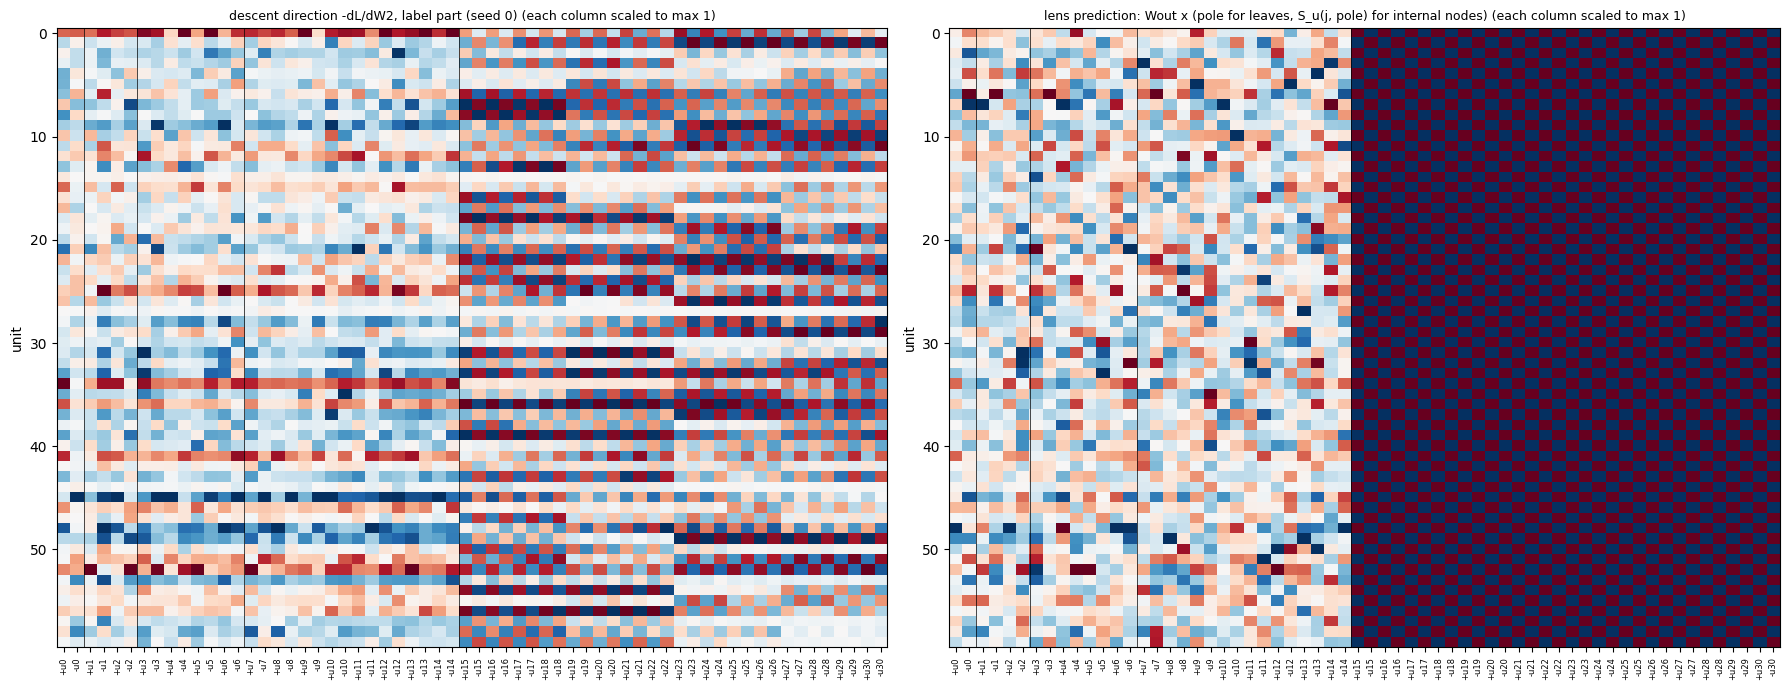

per-level correlation between the two panels (over units x features): L0: 0.802, L1: 0.653, L2: 0.481, L3: 0.365, L4: 0.842
gradient on the ideal rows: fraction of |G1 row| along the row's own direction (norm change) vs off it, by level: L0: 0.15, L1: 0.10, L2: 0.08, L3: 0.10, L4: 0.16


In [3]:
# The descent direction on W2 for seed 0, in the feature basis (units x features sorted by node), and the lens prediction next to it.
W1, W2, Wo, D2, S, C, G1 = keep[0]; order = np.lexsort((-np.array([ROW_ID[r][1] for r in range(62)]), np.array([ROW_ID[r][0] for r in range(62)])))
pred = np.zeros_like(D2)
for u in range(60):
    for r in range(62):
        n, p = ROW_ID[r]; pred[u, r] = Wo[0, u] * (p if n >= 15 else S[u, n, 0 if p > 0 else 1])
fig, ax = plt.subplots(1, 2, figsize=(18, 7))
for k, (M, title) in enumerate([(D2, "descent direction -dL/dW2, label part (seed 0)"), (pred, "lens prediction: Wout x (pole for leaves, S_u(j, pole) for internal nodes)")]):
    Ms = M[:, order] / np.abs(M[:, order]).max(0, keepdims=True).clip(1e-12); im = ax[k].imshow(Ms, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto"); ax[k].set_title(title + " (each column scaled to max 1)", fontsize=9)
    ax[k].set_xticks(range(62)); ax[k].set_xticklabels(feature_label[order], rotation=90, fontsize=6); ax[k].set_ylabel("unit")
    for kk in np.cumsum([(feature_level[order] == l).sum() for l in range(4)]): ax[k].axvline(kk - 0.5, color="k", lw=0.5)
plt.tight_layout(); plt.show()
print("per-level correlation between the two panels (over units x features): " + ", ".join(f"L{l}: {np.corrcoef(D2[:, feature_level == l].ravel(), pred[:, feature_level == l].ravel())[0, 1]:.3f}" for l in range(5)))
print(f"gradient on the ideal rows: fraction of |G1 row| along the row's own direction (norm change) vs off it, by level: " + ", ".join(f"L{l}: {np.mean([abs(G1[r] @ W1[r]) / np.linalg.norm(W1[r]) / np.linalg.norm(G1[r]) for r in range(62) if feature_level[r] == l]):.2f}" for l in range(5)))


**Findings (section 1).** The gradient at a random W2 with a +-1 readout has a large label-independent part (logit rms 0.12-0.19, so the
residual is not -y/2), which pushes all of a unit's input weights the same way and hides the structure; the statistics below are for the
label part of the W2 descent (gradient at f -> 0 with the same gates), the actual gradient being the sum of the two.
- **Leaf columns: every unit wants to read the leaves with the sign of its readout.** The descent on W2[u, (m, pole)] has the sign of
  Wout[u] x pole on 96-98% of the entries (63-93% for the actual gradient). A positive-readout unit grows +relu(a_m) and shrinks
  relu(-a_m), i.e. it reads a_m itself: the label-aligned leaf reading of the lens theory, present from the first step.
- **Internal columns follow the unit's leaf half-readings.** The descent on the feature of side `pole` of node j correlates with
  Wout[u] x S_u(j, pole) at 0.70-0.80 for the root, 0.61-0.65 at level 1, 0.45-0.52 at level 2, 0.32-0.39 at level 3 (over units x
  features, five seeds; the actual gradient: 0.02-0.2). So the converse of the design holds in the lens sense: with ideal features the
  gradient on W2 is set by what the unit already reads from the leaves under each node, side by side, exactly the quantity the designed
  cue blocks were built from. It holds less well with depth, where fewer leaves enter each half-reading and other terms compete.
- **But the first step does not build vetoes.** A veto needs the two poles of a node pushed in opposite directions, with the negative one on
  the side where the unit's leaf reading is opposed to its readout. The two poles get opposite-sign descents on 37-53% of the (unit,
  node) pairs at the root and 28-33% at level 3, around or below chance (0.50), and the predicted sides on 18-35% / 14-17%. A random W2 reads
  both sides of a node with the same sign as often as not, so the first step adds side-dependent weights, not the one-sided vetoes of the
  converged runs; those need the readout and the gates to co-evolve (the lineage of runs 22-25: the W2 sign pattern picks the family).
- **Magnitudes.** The descent rms on internal features falls by a factor 2.1-2.2 per level (1.3e-4 / 6.3e-5 / 2.9e-5 / 1.4e-5), but the
  ideal rows were scaled by 2^(-level), and the W2 gradient is proportional to the feature's norm; per unit norm the ladder is flat
  (1.3 / 1.26 / 1.16 / 1.12 x 1e-4). The gradient on the ideal rows themselves is 85-92% off their own direction (rotation, not norm change).


## 2. Run 60's W2 and W_out with the first layer collapsed onto v: where do the probes get pushed?

Every probe row is s x pole x alpha v (v = u_15 + ... + u_30, pole = the probe's designed pole, s = +-1 a global sign convention) and every cue
row is pole x (alpha v + epsilon u_m) (its designed identity, as the cue init pole x (v + u_j) of runs 37-62). The gradient on the 30 probe
rows is projected on the 31 normals. The lens prediction: the probe of node j is pushed along u_j by its two units' side-contrasts (the
designed blocks, read through the epsilon components), by an amount proportional to epsilon and with the designed pole, and along v by the
coherent leaf signal, independent of epsilon.

**The scalar cannot be chosen by minimising the log loss: the loss is flat.** At every scalar multiple of v the design's quadruple symmetry
makes the four units of a node cancel almost exactly (the logit rms stays at 0.02 for alpha from 0.02 to 1, E[f y] is of order 1e-5 with a
sign set by s), so the log loss is log 2 + O(1e-5) for every alpha and the minimiser is alpha = 0, where the probes are zero rows with no
gradient at all. Two degeneracies feed this. At epsilon = 0 every unit's cue block is side-balanced, so its reading of the cue features
(all +-alpha v) cancels, its own probe contributes -alpha relu(+-v . x) and the unit is dead on every point. And if the two probes of a
node were given the same sign, the two units (B, +) and (B, -) of the node would have identical inputs and opposite readouts and the logit
would vanish identically. The cells below show the flat loss curves and then analyse the gradient at the init scale, alpha = sqrt 2 / |v|
(row norm sqrt 2, as run 60's rows), with s = -1 (the convention with E[f y] > 0); the direction of the probe push is what matters, and
it is checked against alpha and s at the end.


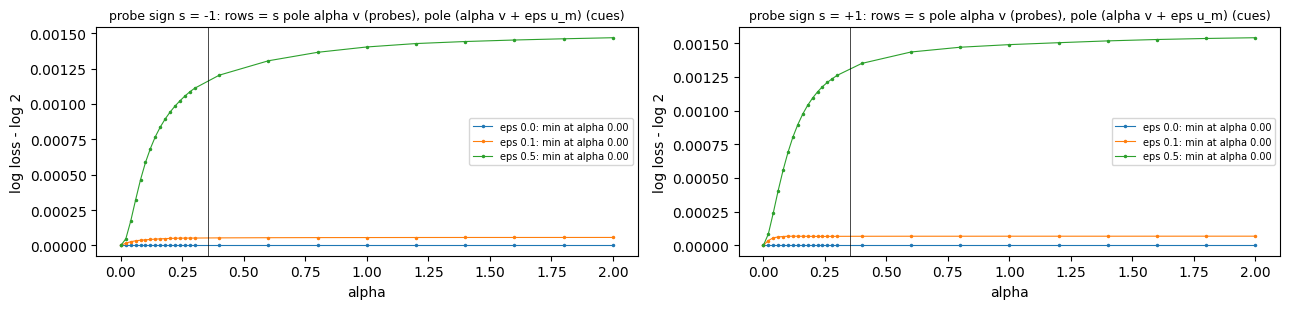

alpha used below: 0.3536 (row norm sqrt 2); the loss-minimising alpha is 0 for every eps and sign


In [4]:
def v_first_layer(alpha, eps, probe_sign=-1):
    W1 = np.zeros((62, 100))
    for p_ in PROBE_ROWS: W1[p_] = probe_sign * HIERARCHY_TARGETS[p_][1] * alpha * v                                 # probes: s x pole x alpha v (the two probes of a node opposite)
    for (m, pole), r in CUE_ID.items(): W1[r] = pole * (alpha * v + eps * U[m])
    return W1
EPS_LIST = (0.0, 0.02, 0.05, 0.1, 0.2, 0.5); ALPHA0 = float(np.sqrt(2) / np.linalg.norm(v)); grid = np.concatenate([np.linspace(0.0, 0.3, 16), np.linspace(0.4, 2.0, 9)])
fig, ax = plt.subplots(1, 2, figsize=(13, 3.2))
for k, s_ in enumerate((-1, +1)):
    for eps in (0.0, 0.1, 0.5):
        losses = [population_gradient(v_first_layer(a, eps, s_), W2_60, Wo_60)[0] for a in grid]; ax[k].plot(grid, np.array(losses) - np.log(2), ".-", ms=3, lw=0.8, label=f"eps {eps}: min at alpha {grid[int(np.argmin(losses))]:.2f}")
    ax[k].set_xlabel("alpha"); ax[k].set_ylabel("log loss - log 2"); ax[k].set_title(f"probe sign s = {s_:+d}: rows = s pole alpha v (probes), pole (alpha v + eps u_m) (cues)", fontsize=9); ax[k].legend(fontsize=7); ax[k].axvline(ALPHA0, color="k", lw=0.5)
plt.tight_layout(); plt.show()
print(f"alpha used below: {ALPHA0:.4f} (row norm sqrt 2); the loss-minimising alpha is 0 for every eps and sign")


In [5]:
def probe_push_table(eps, alpha=ALPHA0, probe_sign=-1):
    W1 = v_first_layer(alpha, eps, probe_sign); loss, (G1, G2, Go) = population_gradient(W1, W2_60, Wo_60); D = -G1[PROBE_ROWS]; Cp = D @ U.T                       # push of each probe on the 31 normals
    vhat = v / np.linalg.norm(v); rows = []
    for p in PROBE_ROWS:
        j, pole = HIERARCHY_TARGETS[p]; leaf = np.sqrt(np.mean(Cp[p, 15:] ** 2)); internal = Cp[p, :15]; others = np.delete(internal, j)
        rows.append({"probe": p, "level": NODE_LEVEL[j], "target": f"{'+' if pole > 0 else '-'}u{j}", "push on target (signed by pole)": pole * Cp[p, j], "push along v": D[p] @ vhat, "leaf rms": leaf, "largest other internal |push|": np.abs(others).max(), "node of largest other": int(np.delete(np.arange(15), j)[np.abs(others).argmax()]),
                     "off-span push": np.linalg.norm(D[p] - Cp[p] @ U), "|push|": np.linalg.norm(D[p])})
    t = pd.DataFrame(rows); t["target / leaf rms"] = t["push on target (signed by pole)"] / t["leaf rms"]; t["target / |push|"] = t["push on target (signed by pole)"] / t["|push|"]
    return loss, t, Cp
def forward_hidden(W1, n=100_000):
    with torch.no_grad(): return torch.relu(torch.relu(X[:n] @ torch.as_tensor(W1, dtype=torch.float32, device=dev).T) @ torch.as_tensor(W2_60, dtype=torch.float32, device=dev).T).cpu().numpy()
summary = []
for eps, alpha, s_ in [(e, ALPHA0, -1) for e in EPS_LIST] + [(0.1, ALPHA0, +1), (0.1, 0.1, -1), (0.1, 1.0, -1)]:
    loss, t, Cp = probe_push_table(eps, alpha, s_); g = t.groupby("level"); act = float((forward_hidden(v_first_layer(alpha, eps, s_)) > 0).mean())
    summary.append({"eps": eps, "alpha": round(alpha, 3), "s": s_, "loss": round(loss, 5), "unit active frac": round(act, 3), "probes whose largest internal push is the target, with the designed pole": int(((t["push on target (signed by pole)"] > 0) & (t["push on target (signed by pole)"].abs() > t["largest other internal |push|"])).sum()),
                    "target push / leaf rms by level 0/1/2/3 (mean)": " / ".join(f"{g['target / leaf rms'].mean()[l]:.2f}" for l in range(4)), "target push / |push| by level": " / ".join(f"{g['target / |push|'].mean()[l]:.2f}" for l in range(4)),
                    "push along v / |push| (mean)": round(float((t["push along v"] / t["|push|"]).mean()), 3), "off-span / |push| (mean)": round(float((t["off-span push"] / t["|push|"]).mean()), 3)})
print(pd.DataFrame(summary).to_string(index=False))
loss, t, Cp = probe_push_table(0.1); print(f"\neps = 0.1, per probe:"); print(t.round(5).to_string(index=False))


 eps  alpha  s    loss  unit active frac  probes whose largest internal push is the target, with the designed pole target push / leaf rms by level 0/1/2/3 (mean) target push / |push| by level  push along v / |push| (mean)  off-span / |push| (mean)
0.00  0.354 -1 0.69315             0.105                                                                         0                          nan / nan / nan / nan         nan / nan / nan / nan                           NaN                       NaN
0.02  0.354 -1 0.69315             0.252                                                                        22                      7.46 / 5.14 / 3.81 / 2.52     0.63 / 0.46 / 0.31 / 0.23                         0.000                     0.780
0.05  0.354 -1 0.69316             0.254                                                                        30                     12.18 / 8.99 / 6.68 / 4.56     0.77 / 0.63 / 0.52 / 0.39                         0.000                     0.726
0.10  0.

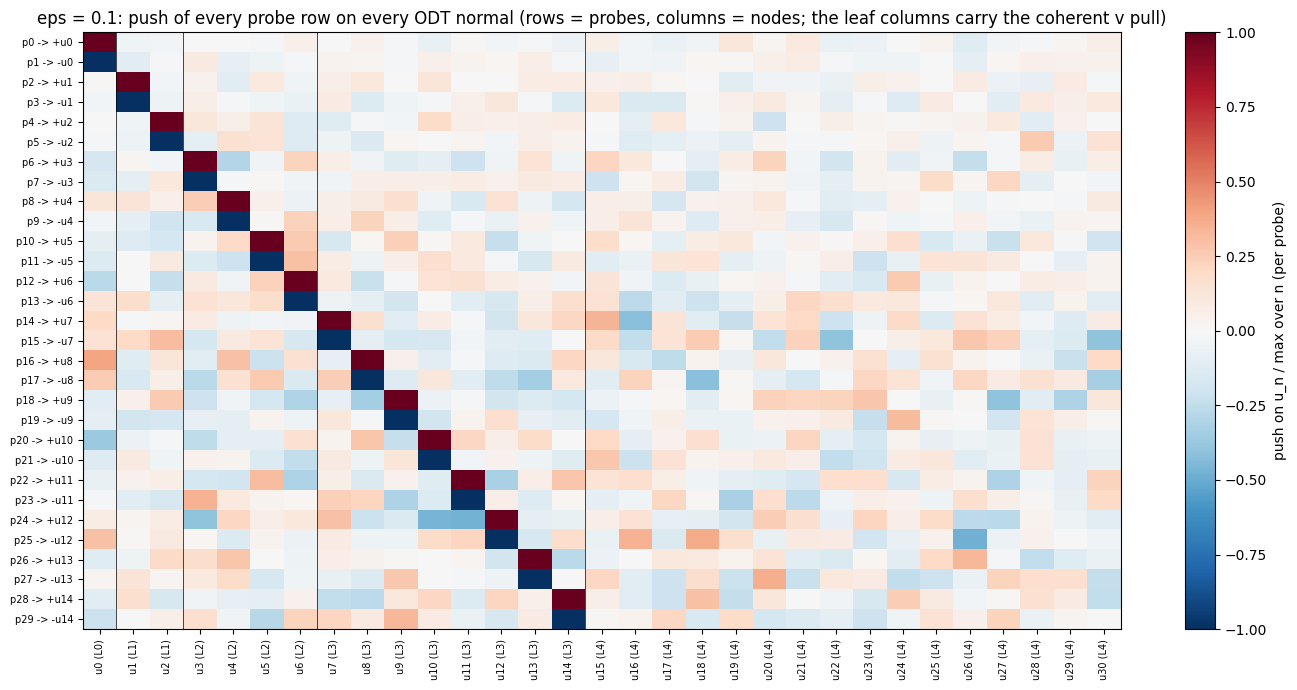

In [6]:
# The probes' pushes on the 31 normals for eps = 0.1 (rows: probes in design order, columns: nodes), signed so that + means toward the designed pole of the probe's own target.
loss, t, Cp = probe_push_table(0.1); M = Cp / np.abs(Cp).max(1, keepdims=True)
fig, ax = plt.subplots(figsize=(14, 7)); im = ax.imshow(M, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto"); plt.colorbar(im, ax=ax, label="push on u_n / max over n (per probe)")
ax.set_xticks(range(31)); ax.set_xticklabels([f"u{n} (L{NODE_LEVEL[n]})" for n in range(31)], rotation=90, fontsize=7); ax.set_yticks(range(30)); ax.set_yticklabels([f"p{p} -> {'+' if HIERARCHY_TARGETS[p][1] > 0 else '-'}u{HIERARCHY_TARGETS[p][0]}" for p in range(30)], fontsize=7)
for kk in (1, 3, 7, 15): ax.axvline(kk - 0.5, color="k", lw=0.5)
ax.set_title("eps = 0.1: push of every probe row on every ODT normal (rows = probes, columns = nodes; the leaf columns carry the coherent v pull)"); plt.tight_layout(); plt.show()


**Findings (section 2).** At the init scale (row norm sqrt 2) the population push on every probe row points at its designed node with its
designed pole, and at nothing else.
- **Every probe is pushed to its target.** For epsilon >= 0.05 all 30 probes have their largest internal component on their designed node
  with the designed pole (22 of 30 at epsilon 0.02); at epsilon 0.1 the target carries 87 / 77 / 63 / 53% of the push's norm by level, the
  rest being sampling noise (next point). The push along v is zero to three decimals: the coherent leaf signal cancels on the probes within
  each node's quadruple (two units of opposite readout read the same probe through blocks of opposite sign), so unlike a random row, a
  designed probe feels no pull toward v or toward any leaf at first order.
- **The other components are noise.** Doubling the sample from 400k to 1.6M leaves the target push at 6.5e-5 and halves the leaf rms
  (7.5e-6 -> 4.1e-6), the off-span part (6.6e-5 -> 3.3e-5) and the other-internal rms (7.8e-6 -> 4.1e-6), all as 1 / sqrt n; another seed
  gives the same. So the "target / leaf rms" ratios in the table (18 / 13 / 10 / 6 by level at epsilon 0.1, 24 / 16 / 11 / 8 at 0.2) are
  lower bounds set by the sample, and the population push is along the target alone. The ladder by level is the design's contrast count
  (2^(4 - level) cues under the node), and the push grows with epsilon up to 0.2 and saturates by 0.5 (the epsilon term starts to
  dominate the cue features). It also grows as alpha shrinks (24 at alpha 0.1, 18 at 0.35, 9 at 1.0, in leaf-rms units): the smaller the
  v component, the larger the overlap of the probe's gate with its units' gates.
- **Sign convention and scale.** The probe sign s only flips the sign of E[f y] (both conventions give the same push structure, the loss
  is flat either way); the loss-minimising alpha is 0 for every epsilon, so "the scalar that minimises the log loss" is not a usable
  definition at this configuration. The design's job is visible instead: the cue components of size epsilon are the only thing the
  probes see, and they see them as a push straight at their node.
